In [1302]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

## LOAD DATA

In [1303]:
df = pd.read_csv("train.csv")

df.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## Understand Data

In [1304]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    str    
 4   Sex          891 non-null    str    
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    str    
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    str    
 11  Embarked     889 non-null    str    
dtypes: float64(2), int64(5), str(5)
memory usage: 118.9 KB


In [1305]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [1306]:
df.columns

Index(['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp',
       'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked'],
      dtype='str')

In [1307]:
df.isna().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [1308]:
df.drop(columns=['PassengerId'], inplace=True)

<Axes: xlabel='Sex', ylabel='count'>

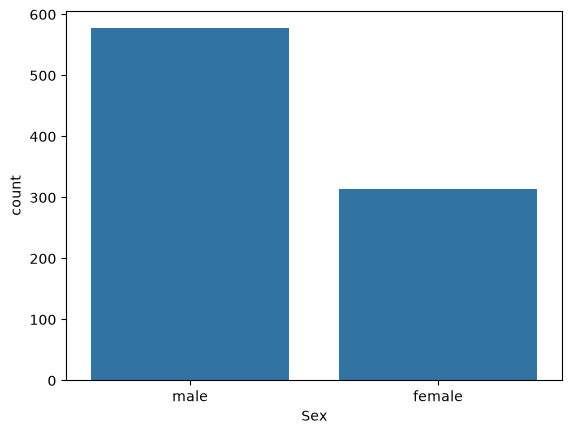

In [1309]:
df['Sex'].value_counts()
sns.countplot(data=df, x='Sex')

<Axes: xlabel='Survived', ylabel='count'>

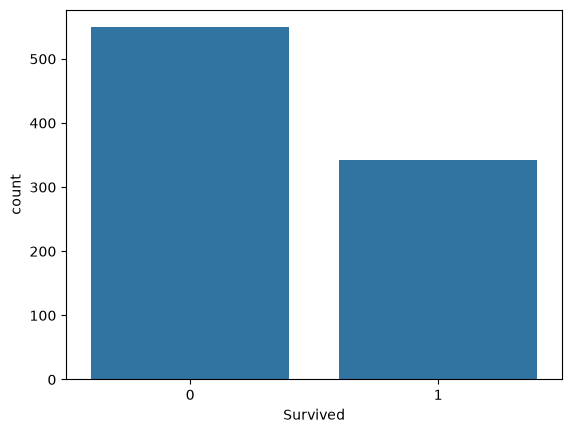

In [1310]:
df['Survived'].value_counts()
sns.countplot(data=df, x='Survived')

<Axes: xlabel='Embarked', ylabel='count'>

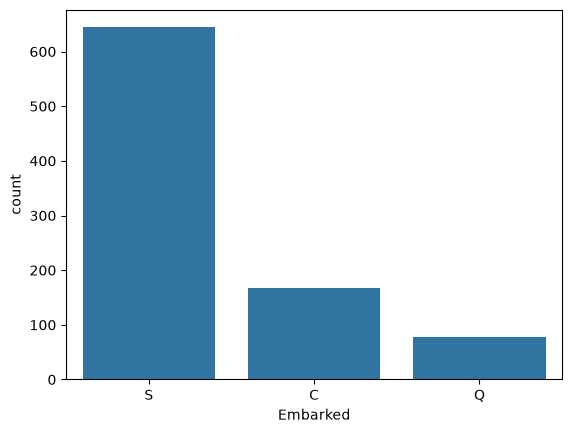

In [1311]:
df['Embarked'].value_counts()
sns.countplot(data=df, x='Embarked')

In [1312]:
df.duplicated().sum()

np.int64(0)

In [1313]:
df['Deck'] = df['Cabin'].str[0]

In [1314]:
df['Deck'] = df['Deck'].fillna(value='Unknown')

In [1315]:
df = df.drop(columns='Cabin')

In [1316]:
df.shape

(891, 11)

## Outliers

In [1317]:
q1 = df['Age'].quantile(0.25)
q3 = df['Age'].quantile(0.75)

IQR = q3 - q1

lower_bound = q1 - 1.5 * IQR
upper_bound = q3 + 1.5 * IQR

outliers = df[(df['Age'] < lower_bound) | (df['Age'] > upper_bound)]
outliers

,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck
33,0,2,"Wheadon, Mr. Edward H",male,66.0,0,0,C.A. 24579,10.5000,S,Unknown
54,0,1,"Ostby, Mr. Engelhart Cornelius",male,65.0,0,1,113509,61.9792,C,B
96,0,1,"Goldschmidt, Mr. George B",male,71.0,0,0,PC 17754,34.6542,C,A
116,0,3,"Connors, Mr. Patrick",male,70.5,0,0,370369,7.7500,Q,Unknown
280,0,3,"Duane, Mr. Frank",male,65.0,0,0,336439,7.7500,Q,Unknown
456,0,1,"Millet, Mr. Francis Davis",male,65.0,0,0,13509,26.5500,S,E
493,0,1,"Artagaveytia, Mr. Ramon",male,71.0,0,0,PC 17609,49.5042,C,Unknown
630,1,1,"Barkworth, Mr. Algernon Henry Wilson",male,80.0,0,0,27042,30.0000,S,A
672,0,2,"Mitchell, Mr. Henry Michael",male,70.0,0,0,C.A. 24580,10.5000,S,Unknown
745,0,1,"Crosby, Capt. Edward Gifford",male,70.0,1,1,WE/P 5735,71.0000,S,B


<Axes: xlabel='Age'>

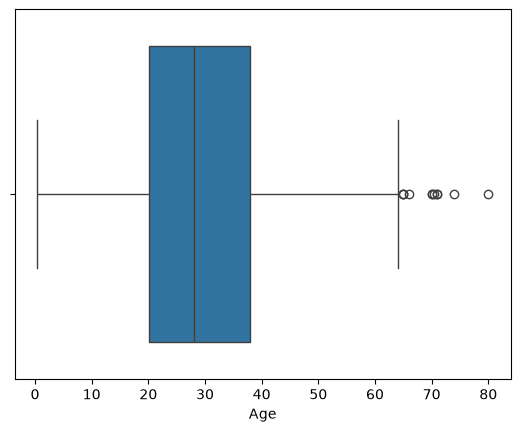

In [1318]:
sns.boxplot(data=df, x='Age')

I will not delete the outliers because it is important 

### Spliting Train and Test

In [1319]:
x = df.drop(columns='Survived')
y = df['Survived']

In [1320]:
x.head()

,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked,Deck
0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,S,Unknown
1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C,C
2,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,S,Unknown
3,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,S,C
4,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,S,Unknown


In [1321]:
x.shape

(891, 10)

In [1322]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [1323]:
y.shape

(891,)

In [1324]:
from sklearn.model_selection import train_test_split

In [1325]:
x_train, x_test, y_train, y_test = train_test_split(x,y , test_size=0.2, random_state=42)

In [1326]:
x_train.shape

(712, 10)

In [1327]:
x_test.shape

(179, 10)

In [1328]:
y_train.shape

(712,)

In [1329]:
y_test.shape

(179,)

## Feature Engineering

In [1330]:
x_train['Title'] = x_train['Name'].str.extract(r',\s*([^.]*)\.')

x_test['Title'] = x_test['Name'].str.extract(r',\s*([^.]*)\.')

In [1331]:
title_mapping = {
    'Mlle': 'Miss',
    'Ms': 'Miss',
    'Mme': 'Mrs',
    'Lady': 'Royalty',
    'the Countess': 'Royalty',
    'Dr': 'Other',
    'Rev': 'Other',
    'Major': 'Other',
    'Col': 'Other',
    'Capt': 'Other'
}

x_train['Title'] = x_train['Title'].replace(title_mapping)
x_test['Title'] = x_test['Title'].replace(title_mapping)

In [1332]:
x_train.drop(columns='Name', inplace=True)
x_test.drop(columns='Name', inplace=True)

In [1333]:
x_train['Ticket_Prefix'] = (
    x_train['Ticket']
    .str.extract(r'^([A-Za-z][A-Za-z0-9./]*(?:\s+\d+\.)?)')[0]
    .str.strip()
    .fillna('Numeric')
)
x_test['Ticket_Prefix'] = (
    x_test['Ticket']
    .str.extract(r'^([A-Za-z][A-Za-z0-9./]*(?:\s+\d+\.)?)')[0]
    .str.strip()
    .fillna('Numeric')
)


In [1334]:
x_train['Ticket_Prefix'] = x_train['Ticket_Prefix'].str.upper()
x_test['Ticket_Prefix'] = x_test['Ticket_Prefix'].str.upper()

In [1335]:
x_train.drop(columns='Ticket', inplace=True)
x_test.drop(columns='Ticket', inplace=True)

In [1336]:
x_train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Deck,Title,Ticket_Prefix
331,1,male,45.5,0,0,28.5000,S,C,Mr,NUMERIC
733,2,male,23.0,0,0,13.0000,S,Unknown,Mr,NUMERIC
382,3,male,32.0,0,0,7.9250,S,Unknown,Mr,STON/O 2.
704,3,male,26.0,1,0,7.8542,S,Unknown,Mr,NUMERIC
813,3,female,6.0,4,2,31.2750,S,Unknown,Miss,NUMERIC


## Encoding

In [1369]:
Embarked_mode = x_train['Embarked'].mode()[0]

In [1370]:
x_train['Embarked'] = x_train['Embarked'].fillna(Embarked_mode)
x_test['Embarked'] = x_test['Embarked'].fillna(Embarked_mode)

In [1339]:
from sklearn.preprocessing import LabelEncoder, OneHotEncoder

In [1340]:
# 1 - Call
le = LabelEncoder()
on = OneHotEncoder(handle_unknown='ignore', sparse_output=False)

In [1341]:
# 2 - Use
x_train['Sex'] = le.fit_transform(x_train['Sex'])
x_test['Sex'] = le.transform(x_test['Sex'])

In [1342]:
x_train['Embarked'] = le.fit_transform(x_train['Embarked'])
x_test['Embarked'] = le.transform(x_test['Embarked'])

In [1343]:
x_train['Deck'] = le.fit_transform(x_train['Deck'])
x_test['Deck'] = le.transform(x_test['Deck'])

In [1344]:
train_encoded = on.fit_transform(x_train[['Title']])
test_encoded = on.transform(x_test[['Title']])

In [1345]:
title_columns = on.get_feature_names_out()

In [1346]:
train_encoded = pd.DataFrame(
    train_encoded,
    columns=title_columns,
    index=x_train.index
)

test_encoded = pd.DataFrame(
    test_encoded,
    columns=title_columns,
    index=x_test.index
)

In [1347]:
x_train = pd.concat([x_train, train_encoded], axis=1)
x_test = pd.concat([x_test, test_encoded], axis=1)

In [1348]:
x_train.drop(columns='Title', inplace=True)
x_test.drop(columns='Title', inplace=True)

In [1349]:
train_encoded = on.fit_transform(x_train[['Ticket_Prefix']])
test_encoded = on.transform(x_test[['Ticket_Prefix']])

In [1350]:
train_encoded = pd.DataFrame(
    train_encoded,
    columns=on.get_feature_names_out(['Ticket_Prefix']),
    index=x_train.index
)

test_encoded = pd.DataFrame(
    test_encoded,
    columns=on.get_feature_names_out(['Ticket_Prefix']),
    index=x_test.index
)

In [1351]:
x_train = pd.concat([x_train, train_encoded], axis=1)
x_test = pd.concat([x_test, test_encoded], axis=1)

In [1352]:
x_train.drop(columns='Ticket_Prefix', inplace=True)
x_test.drop(columns='Ticket_Prefix', inplace=True)

In [1353]:
x_train.head()

,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Deck,Title_Master,Title_Miss,...,Ticket_Prefix_SOTON/O.Q.,Ticket_Prefix_SOTON/O2,Ticket_Prefix_SOTON/OQ,Ticket_Prefix_STON/O 2.,Ticket_Prefix_STON/O2.,Ticket_Prefix_SW/PP,Ticket_Prefix_W./C.,Ticket_Prefix_W.E.P.,Ticket_Prefix_W/C,Ticket_Prefix_WE/P
331,1,1,45.5,0,0,28.5000,2,2,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
733,2,1,23.0,0,0,13.0000,2,8,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
382,3,1,32.0,0,0,7.9250,2,8,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0
704,3,1,26.0,1,0,7.8542,2,8,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
813,3,0,6.0,4,2,31.2750,2,8,0.0,1.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [1354]:
x_train['Sex'].value_counts()

Sex
1    467
0    245
Name: count, dtype: int64

In [1355]:
x_train['Embarked'].value_counts()

Embarked
2    525
0    125
1     60
3      2
Name: count, dtype: int64

In [1356]:
x_train['Deck'].value_counts()

Deck
8    553
2     52
1     38
4     24
3     19
5     12
0     10
6      3
7      1
Name: count, dtype: int64

## Scaling 

In [1357]:
x_train.info()

<class 'pandas.DataFrame'>
Index: 712 entries, 331 to 102
Data columns (total 55 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Pclass                    712 non-null    int64  
 1   Sex                       712 non-null    int64  
 2   Age                       572 non-null    float64
 3   SibSp                     712 non-null    int64  
 4   Parch                     712 non-null    int64  
 5   Fare                      712 non-null    float64
 6   Embarked                  712 non-null    int64  
 7   Deck                      712 non-null    int64  
 8   Title_Master              712 non-null    float64
 9   Title_Miss                712 non-null    float64
 10  Title_Mr                  712 non-null    float64
 11  Title_Mrs                 712 non-null    float64
 12  Title_Other               712 non-null    float64
 13  Title_Royalty             712 non-null    float64
 14  Ticket_Prefix_A./5.     

In [1358]:
x_train['Age'].isna().sum()

np.int64(140)

In [1359]:
age_median = x_train['Age'].median()
age_median

np.float64(28.0)

In [1360]:
x_train['Age'] = x_train['Age'].fillna(age_median)
x_test['Age'] = x_test['Age'].fillna(age_median)

In [1361]:
x_train['Age'].isna().sum()

np.int64(0)

In [1362]:
x_test['Age'].isna().sum()

np.int64(0)

In [1363]:
from sklearn.preprocessing import RobustScaler

In [1364]:
# 1 - Call
rs = RobustScaler()

In [1365]:
# 2 - Use
num_col = ['Age', 'SibSp', 'Parch', 'Fare']

x_train[num_col] = rs.fit_transform(x_train[num_col])
x_test[num_col] = rs.transform(x_test[num_col])

In [1366]:
x_train[num_col].head()

,Age,SibSp,Parch,Fare
331,1.346154,0.0,0.0,0.622184
733,-0.384615,0.0,0.0,-0.064416
382,0.307692,0.0,0.0,-0.289223
704,-0.153846,1.0,0.0,-0.292359
813,-1.692308,4.0,2.0,0.745107


## Imbalance

In [1367]:
y_train.value_counts()

Survived
0    444
1    268
Name: count, dtype: int64

<Axes: xlabel='Survived', ylabel='count'>

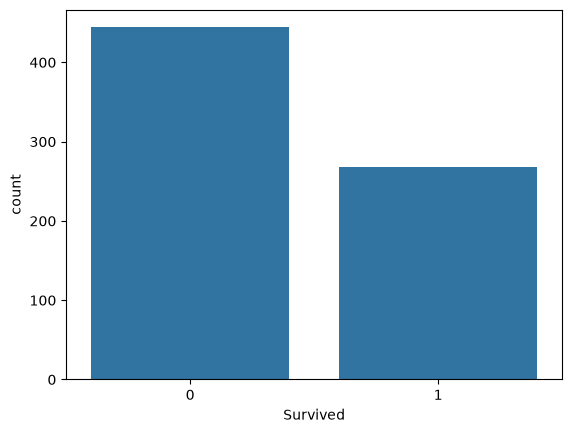

In [1368]:
sns.countplot(x =y_train)

Checked the target distribution (Survived).

Class 0: 444 (62.36%).

Class 1: 268 (37.64%).

Observed a moderate class imbalance.

No resampling techniques applied because the imbalance was not severe

## Finish !